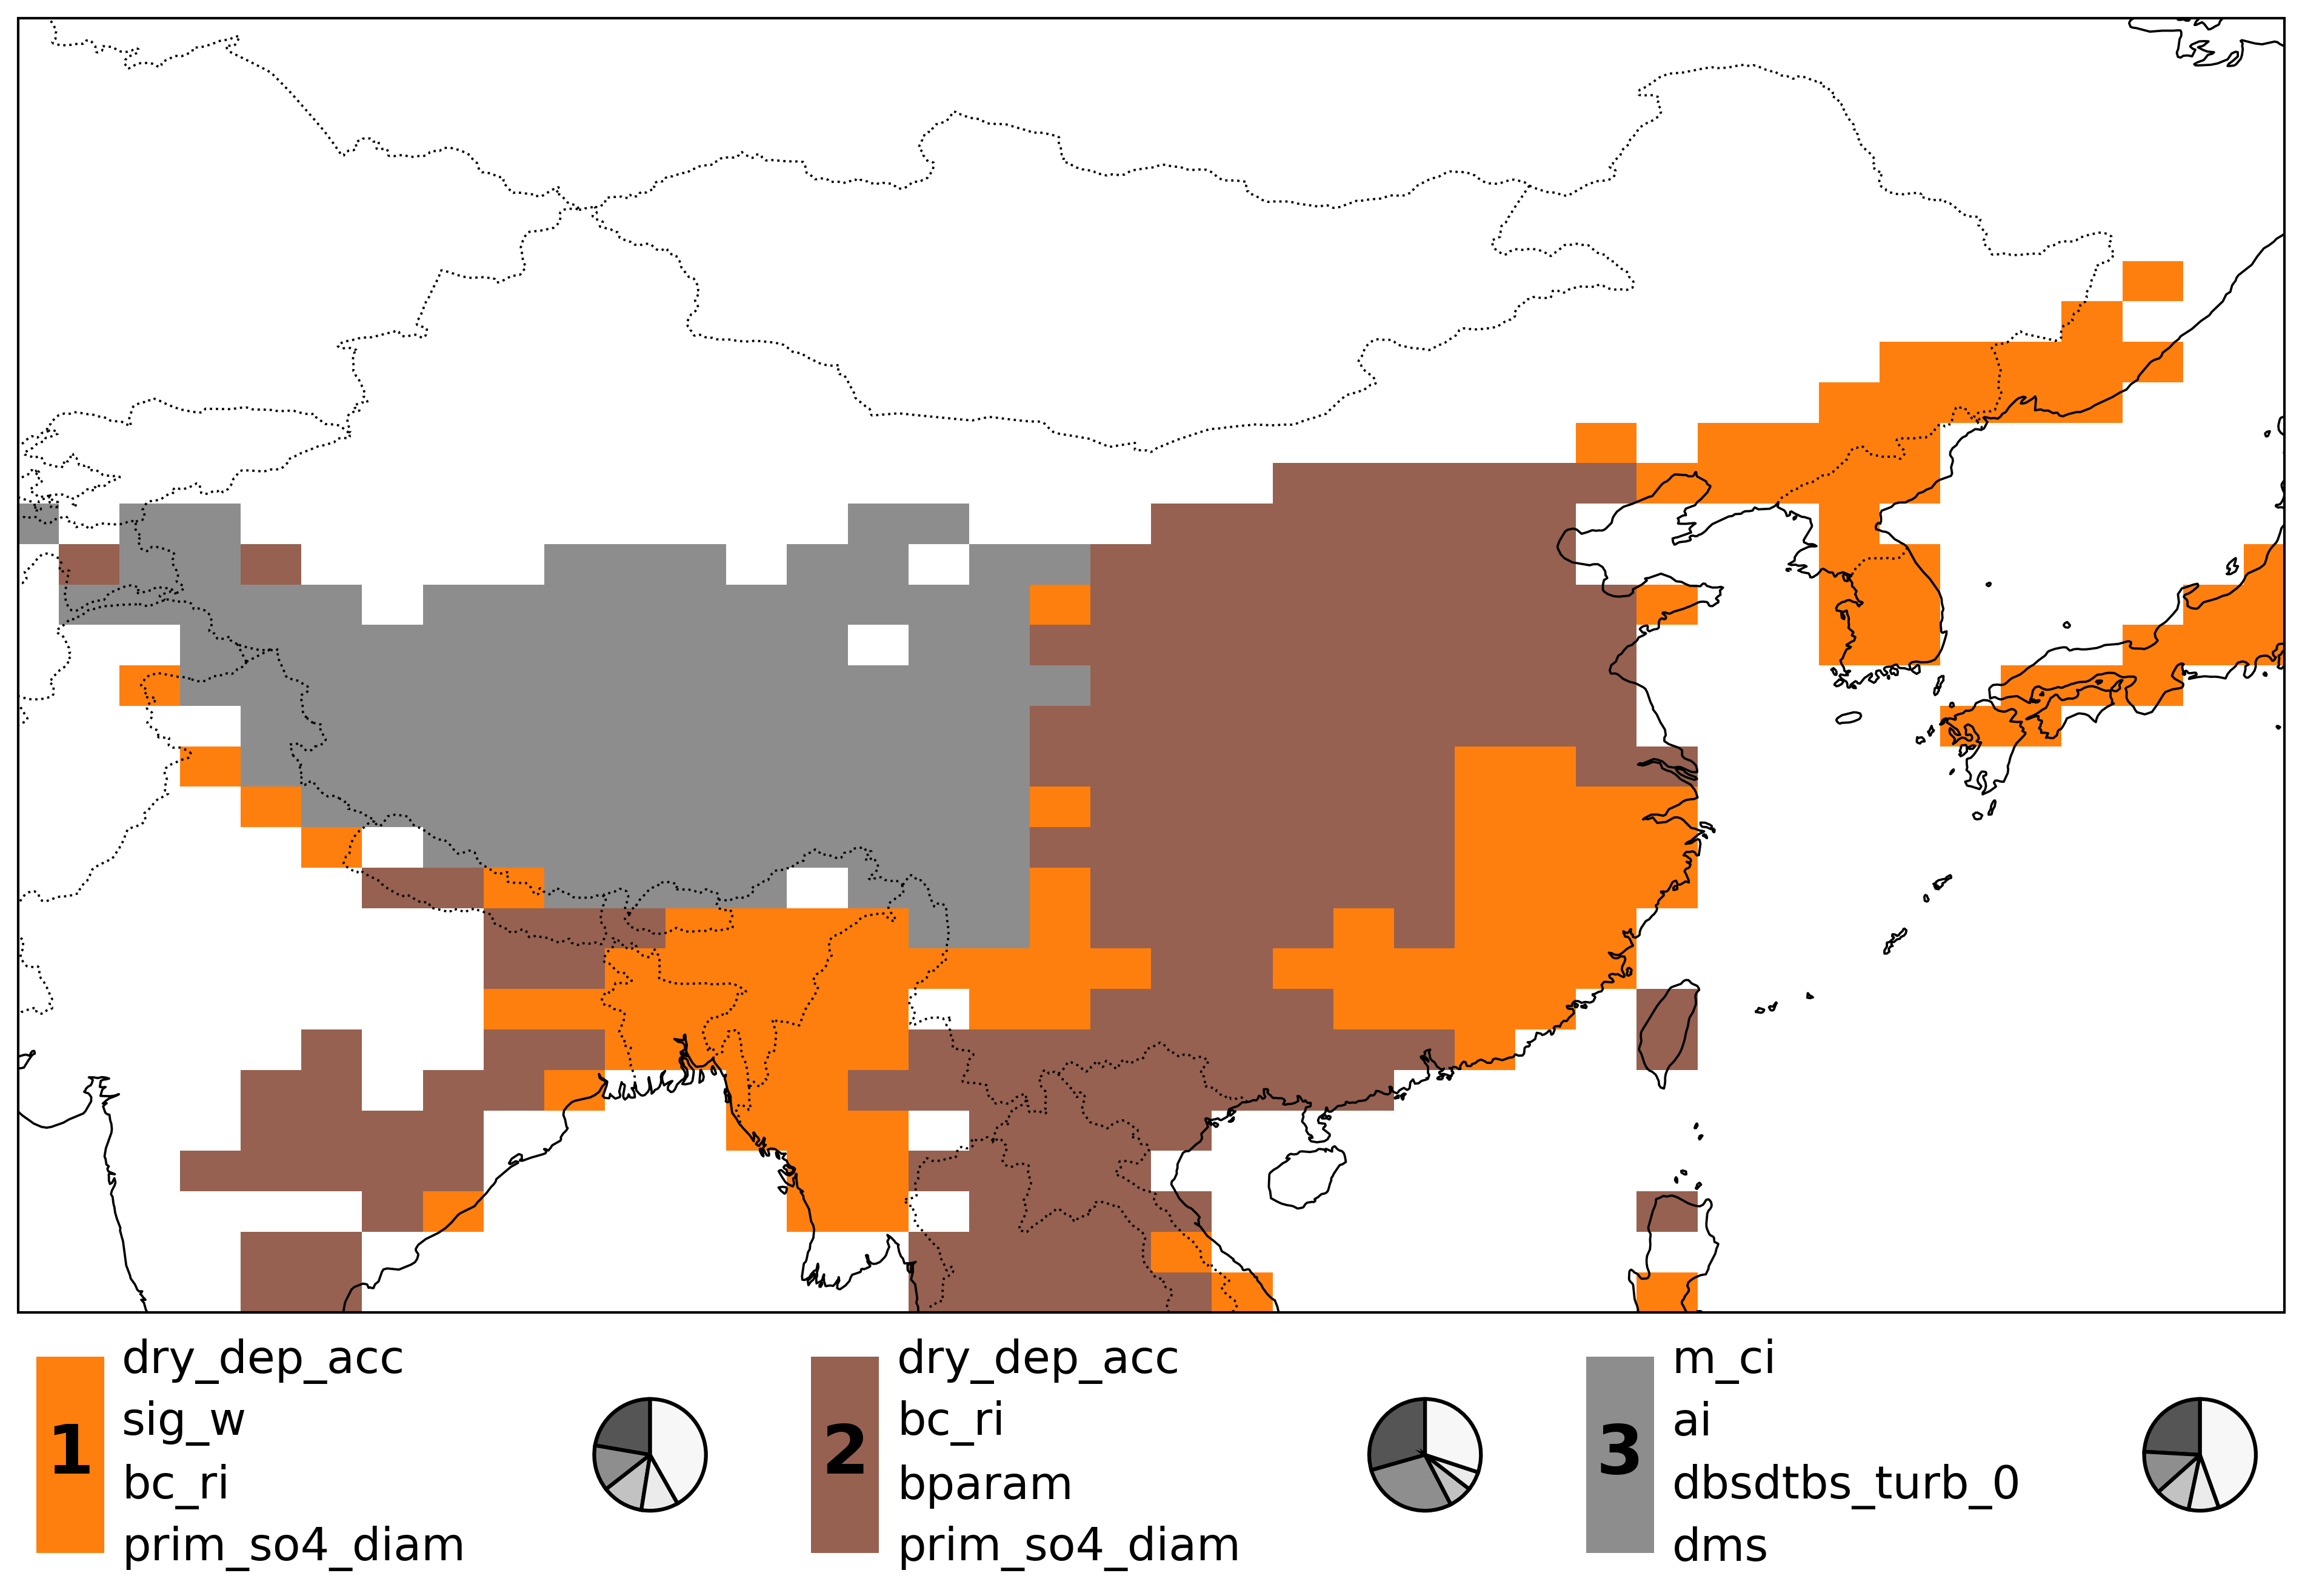

In [2]:

import os
import struct
import numpy as np
import xarray as xr
import pandas as pd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

from scipy.io import FortranFile
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Rectangle


# ==========================================
# CONFIGURATION
# ==========================================

cluster_path = "/home/users/jianxing/ERFaci_optimal_constraint_clusters.nc"

land_path = "/home/users/jianxing/Step1_data/For_Jianxing/N96_land.pp"

infile = (
    "/gws/ssde/j25a/acure/jianxing/aci/"
    "GAM_values/ACI/cluster_ann_summary/"
    "ACI_ann_cluster_mean_contribution_optimal_constrained.csv"
)

cluster_ids = [1.0, 5.0, 7.0]
target_clusters = ["c1", "c5", "c7"]

top_n = 4


# ==========================================
# CLUSTER COLORS
# ==========================================

cluster_color_map = {
    "c1": "#ff7f0e",
    "c5": "#966150",
    "c7": "#8d8d8d"
}

cluster_cmap = ListedColormap([
    cluster_color_map["c1"],
    cluster_color_map["c5"],
    cluster_color_map["c7"]
])

cluster_cmap.set_bad("white")

cluster_bounds = [0.5, 3.0, 6.0, 7.5]

cluster_norm = BoundaryNorm(
    cluster_bounds,
    cluster_cmap.N
)


# ==========================================
# PIE CHART COLORS
# ==========================================

bg_color = "white"

top_pie_colors = [
    "#555555",
    "#8e8e8e",
    "#c2c2c2",
    "#ebebeb"
]

others_color = "#f7f7f7"


# ==========================================
# FONT AND LAYOUT SETTINGS
# ==========================================

parameter_fontsize = 18
cluster_number_fontsize = 27

figure_size = (13.5, 8.8)

pie_linewidth = 1.5


# ==========================================
# CHECK INPUT FILES
# ==========================================

for path in [cluster_path, land_path, infile]:

    if not os.path.isfile(path):

        raise FileNotFoundError(
            f"Input file not found: {path}"
        )


# ==========================================
# READ UM PP LAND MASK WITHOUT IRIS
# ==========================================

def read_pp_land_mask(filename):
    """
    Read an uncompressed 2D land mask in the Met Office UM PP format.

    Only standard uncompressed 32-bit PP records are supported.

    Read the following metadata from the PP header:
        LBROW : latitude size
        LBNPT : longitude size
        LBPACK: packing code
        BZY   : zeroth latitude
        BDY   : latitude interval
        BZX   : zeroth longitude
        BDX   : longitude interval

    Raise an error for unsupported formats rather than using invalid data.
    """

    # --------------------------------------
    # DETECT BYTE ORDER
    # --------------------------------------

    with open(filename, "rb") as f:
        first_four = f.read(4)

    if len(first_four) != 4:
        raise ValueError("Invalid or empty PP file.")

    if struct.unpack(">I", first_four)[0] == 256:
        endian = ">"

    elif struct.unpack("<I", first_four)[0] == 256:
        endian = "<"

    else:
        raise ValueError(
            "Unsupported PP format: expected a "
            "256-byte standard 32-bit PP header."
        )

    # --------------------------------------
    # READ FORTRAN RECORDS
    # --------------------------------------

    pp = FortranFile(
        filename,
        "r",
        header_dtype=np.dtype(endian + "u4")
    )

    try:
        header_bytes = pp.read_record(np.uint8).tobytes()
        data_bytes = pp.read_record(np.uint8).tobytes()

    finally:
        pp.close()

    if len(header_bytes) != 256:
        raise ValueError(
            "Unexpected PP header length."
        )

    # --------------------------------------
    # INTERPRET HEADER
    # --------------------------------------

    int_header = np.frombuffer(
        header_bytes[:45 * 4],
        dtype=endian + "i4"
    )

    real_header = np.frombuffer(
        header_bytes[45 * 4:],
        dtype=endian + "f4"
    )

    nlat = int(int_header[17])
    nlon = int(int_header[18])
    lbpack = int(int_header[20])
    lbuser_type = int(int_header[38])

    if not (0 < nlat < 10000 and 0 < nlon < 10000):
        raise ValueError(
            f"Invalid PP grid dimensions: {nlat} x {nlon}"
        )

    if lbpack != 0:
        raise ValueError(
            f"PP file uses packing code LBPACK={lbpack}. "
            "This direct reader only supports uncompressed PP data."
        )

    bzy = float(real_header[13])
    bdy = float(real_header[14])
    bzx = float(real_header[15])
    bdx = float(real_header[16])

    if not np.all(np.isfinite([bzy, bdy, bzx, bdx])):
        raise ValueError(
            "Invalid coordinate metadata in PP header."
        )

    if bdy == 0 or bdx == 0:
        raise ValueError(
            "PP file does not contain regular "
            "latitude/longitude increments."
        )

    # --------------------------------------
    # READ DATA
    # --------------------------------------

    npoints = nlat * nlon
    expected_bytes = npoints * 4

    if len(data_bytes) < expected_bytes:
        raise ValueError(
            "PP data record is shorter than expected "
            "from its grid dimensions."
        )

    raw_data = data_bytes[:expected_bytes]

    if lbuser_type in [2, 3, -2, -3]:

        candidate_dtypes = [
            endian + "i4",
            endian + "f4"
        ]

    else:

        candidate_dtypes = [
            endian + "f4",
            endian + "i4"
        ]

    land_values = None

    for dtype in candidate_dtypes:

        candidate = np.frombuffer(
            raw_data,
            dtype=dtype,
            count=npoints
        )

        valid_zero = np.isclose(
            candidate,
            0,
            rtol=0,
            atol=1e-6
        )

        valid_one = np.isclose(
            candidate,
            1,
            rtol=0,
            atol=1e-6
        )

        if (
            np.all(valid_zero | valid_one)
            and np.any(valid_zero)
            and np.any(valid_one)
        ):

            land_values = valid_one.reshape(
                nlat,
                nlon
            )

            break

    if land_values is None:
        raise ValueError(
            "PP data could not be identified as a "
            "binary 0/1 land mask."
        )

    # --------------------------------------
    # BUILD COORDINATES
    # --------------------------------------

    latitudes = (
        bzy
        + bdy * np.arange(
            1,
            nlat + 1,
            dtype=float
        )
    )

    longitudes = (
        bzx
        + bdx * np.arange(
            1,
            nlon + 1,
            dtype=float
        )
    )

    if (
        np.min(latitudes) < -90.1
        or np.max(latitudes) > 90.1
    ):
        raise ValueError(
            "Unexpected latitude coordinates in PP file."
        )

    return (
        land_values,
        latitudes,
        longitudes
    )


# ==========================================
# READ CLUSTER
# ==========================================

with xr.open_dataset(cluster_path) as cluster_ds:

    cluster = cluster_ds["Cluster"].values.copy()

    lat_cl = cluster_ds["latitude"].values.copy()
    lon_cl = cluster_ds["longitude"].values.copy()


# ==========================================
# CONVERT CLUSTER LONGITUDE
# ==========================================

lon_cl_plot = np.where(
    lon_cl > 180,
    lon_cl - 360,
    lon_cl
)

lon_order = np.argsort(lon_cl_plot)

lon_cl_plot = lon_cl_plot[lon_order]
cluster = cluster[:, lon_order]


# ==========================================
# CHINA REGION
# ==========================================

lat_mask = (lat_cl >= 15) & (lat_cl <= 55)
lon_mask = (lon_cl_plot >= 70) & (lon_cl_plot <= 140)

lat_idx = np.where(lat_mask)[0]
lon_idx = np.where(lon_mask)[0]

cluster_cn = cluster[np.ix_(lat_idx, lon_idx)]

lat_cn = lat_cl[lat_idx]
lon_cn = lon_cl_plot[lon_idx]


# ==========================================
# READ LAND MASK
# ==========================================

land_mask_2d, lat_land, lon_land = read_pp_land_mask(
    land_path
)


# ==========================================
# ALIGN LAND LONGITUDE
# ==========================================

lon_land_plot = np.where(
    lon_land > 180,
    lon_land - 360,
    lon_land
)

lon_land_order = np.argsort(lon_land_plot)

lon_land_plot = lon_land_plot[lon_land_order]

land_mask_2d = land_mask_2d[:, lon_land_order]


# ==========================================
# ALIGN LATITUDE
# ==========================================

if lat_land[0] > lat_land[-1]:

    lat_land = lat_land[::-1]

    land_mask_2d = land_mask_2d[::-1, :]


if lat_cl[0] > lat_cl[-1]:

    lat_cl = lat_cl[::-1]

    cluster = cluster[::-1, :]

    lat_mask = (lat_cl >= 15) & (lat_cl <= 55)

    lat_idx = np.where(lat_mask)[0]

    cluster_cn = cluster[np.ix_(lat_idx, lon_idx)]

    lat_cn = lat_cl[lat_idx]


# ==========================================
# INTERPOLATE LAND MASK TO CLUSTER GRID
# ==========================================

land_da = xr.DataArray(
    land_mask_2d.astype(float),
    coords={
        "latitude": lat_land,
        "longitude": lon_land_plot
    },
    dims=["latitude", "longitude"]
)

land_on_cluster = land_da.interp(
    latitude=lat_cn,
    longitude=lon_cn,
    method="nearest"
)

land_cn = land_on_cluster.values == 1


# ==========================================
# LAND-ONLY TARGET CLUSTERS
# ==========================================

cluster_target_mask = np.isin(
    cluster_cn,
    cluster_ids
)

cluster_cn_land = np.where(
    land_cn & cluster_target_mask,
    cluster_cn,
    np.nan
)


# ==========================================
# READ GAM CONTRIBUTION
# ==========================================

df = pd.read_csv(infile)

required_cols = [
    "cluster",
    "param",
    "cluster_pct"
]

missing_cols = [
    col
    for col in required_cols
    if col not in df.columns
]

if missing_cols:

    raise ValueError(
        f"Missing CSV columns: {missing_cols}"
    )


# ==========================================
# CREATE FIGURE
# ==========================================

# Figure background setting:
# Use a white background for the entire figure.

fig = plt.figure(
    figsize=figure_size,
    dpi=300,
    facecolor="white"
)

# Layout of the lower panels:
# Keep the three lower panels at their original relative height.

gs = fig.add_gridspec(
    nrows=2,
    ncols=3,
    height_ratios=[5.0, 0.95],
    hspace=0.025,
    wspace=0.018
)

fig.subplots_adjust(
    left=0.012,
    right=0.988,
    top=0.99,
    bottom=0.015
)


# ==========================================
# TOP PANEL: MAP
# ==========================================

ax_map = fig.add_subplot(
    gs[0, :],
    projection=ccrs.PlateCarree()
)

ax_map.set_facecolor("white")

ax_map.pcolormesh(
    lon_cn,
    lat_cn,
    cluster_cn_land,
    cmap=cluster_cmap,
    norm=cluster_norm,
    shading="auto",
    transform=ccrs.PlateCarree()
)

ax_map.add_feature(
    cfeature.COASTLINE,
    linewidth=0.9,
    edgecolor="black"
)

ax_map.add_feature(
    cfeature.BORDERS,
    linestyle=":",
    linewidth=0.9,
    edgecolor="black"
)

ax_map.set_extent(
    [70, 140, 15, 55],
    crs=ccrs.PlateCarree()
)

ax_map.set_xticks([])
ax_map.set_yticks([])

for spine in ax_map.spines.values():

    spine.set_linewidth(1.0)
    spine.set_edgecolor("black")


# ==========================================
# FUNCTION: BOTTOM PANEL
# ==========================================

def draw_cluster_panel(
    ax,
    cluster_code,
    cluster_number,
    subdf,
    top_n=4
):

    # --------------------------------------
    # SORT CONTRIBUTIONS
    # --------------------------------------

    sub = (
        subdf
        .sort_values(
            "cluster_pct",
            ascending=False
        )
        .reset_index(drop=True)
    )

    top = sub.iloc[:top_n].copy()
    others = sub.iloc[top_n:].copy()

    top_labels = top["param"].tolist()
    top_sizes = top["cluster_pct"].tolist()

    others_sum = others["cluster_pct"].sum()


    # --------------------------------------
    # PANEL STYLE
    # --------------------------------------

    ax.set_facecolor(bg_color)

    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)

    ax.set_xticks([])
    ax.set_yticks([])

    for spine in ax.spines.values():
        spine.set_visible(False)


    # --------------------------------------
    # LEFT COLOR RECTANGLE
    # --------------------------------------

    rect = Rectangle(
        (0.025, 0.10),
        0.095,
        0.80,
        facecolor=cluster_color_map[cluster_code],
        edgecolor="none"
    )

    ax.add_patch(rect)


    # --------------------------------------
    # CLUSTER NUMBER
    # --------------------------------------

    # Cluster-number position:
    # Center the cluster number within its colored rectangle.
    #
    # x = 0.025 + 0.095 / 2 = 0.0725
    # y = 0.10 + 0.80 / 2 = 0.50

    ax.text(
        0.0725,
        0.50,
        str(cluster_number),
        fontsize=cluster_number_fontsize,
        fontweight="bold",
        ha="center",
        va="center",
        color="black",
        family="DejaVu Sans"
    )


    # --------------------------------------
    # TOP 4 PARAMETER NAMES
    # --------------------------------------

    text_x = 0.145

    y_positions = [
        0.88,
        0.63,
        0.37,
        0.12
    ]

    for label, y in zip(
        top_labels,
        y_positions
    ):

        ax.text(
            text_x,
            y,
            label,
            fontsize=parameter_fontsize,
            ha="left",
            va="center",
            color="black",
            family="DejaVu Sans"
        )


    # --------------------------------------
    # PIE DATA
    # --------------------------------------

    pie_sizes = top_sizes.copy()

    pie_colors = top_pie_colors[
        :len(top_sizes)
    ].copy()

    if others_sum > 0:

        pie_sizes.append(
            others_sum
        )

        pie_colors.append(
            others_color
        )


    # --------------------------------------
    # PIE CHART
    # --------------------------------------

    pie_ax = ax.inset_axes([
        0.785,
        0.18,
        0.195,
        0.64
    ])

    pie_ax.pie(
        pie_sizes,
        colors=pie_colors,
        startangle=90,
        counterclock=True,
        wedgeprops=dict(
            edgecolor="black",
            linewidth=pie_linewidth
        )
    )

    pie_ax.set_aspect("equal")
    pie_ax.axis("off")


# ==========================================
# BOTTOM PANELS
# ==========================================

bottom_panel_axes = []

for i, cluster_code in enumerate(
    target_clusters
):

    ax_panel = fig.add_subplot(
        gs[1, i]
    )

    bottom_panel_axes.append(ax_panel)

    sub = df[
        df["cluster"] == cluster_code
    ].copy()

    if sub.empty:

        ax_panel.set_facecolor("white")
        ax_panel.axis("off")

        continue

    draw_cluster_panel(
        ax=ax_panel,
        cluster_code=cluster_code,
        cluster_number=i + 1,
        subdf=sub,
        top_n=top_n
    )


# ==========================================
# ALIGN BOTTOM PANELS WITH THE TOP MAP
# ==========================================

# Align both outer edges with the actual map axes, not the
# full GridSpec width. Keep the original vertical positions.
ax_map.apply_aspect()
map_position = ax_map.get_position()

# Horizontal gap expressed as a fraction of the figure width.
bottom_panel_gap = 0.024
bottom_panel_width = (
    map_position.width - 2.0 * bottom_panel_gap
) / 3.0

for i, ax_panel in enumerate(bottom_panel_axes):

    old_position = ax_panel.get_position()

    panel_left = (
        map_position.x0
        + i * (bottom_panel_width + bottom_panel_gap)
    )

    ax_panel.set_position([
        panel_left,
        old_position.y0,
        bottom_panel_width,
        old_position.height
    ])


# ==========================================
# SHOW ONLY
# ==========================================

plt.show()
plt.close(fig)
